# Análise exploratória — Breast Cancer Wisconsin

Este notebook examina a estrutura, a qualidade e a distribuição dos dados, além das associações entre características e diagnóstico, como etapa inicial do projeto de classificação de câncer de mama.

## 1. Carregamento dos dados

O conjunto de dados é carregado para verificar suas dimensões e os primeiros registros, estabelecendo uma visão inicial das informações disponíveis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/raw/data.csv")

print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())

Linhas: 569
Colunas: 33


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Resultado do carregamento:** a base contém 569 registros e 33 colunas.

## 2. Estrutura e estatísticas descritivas

A inspeção dos tipos e do preenchimento das colunas ajuda a distinguir variáveis numéricas e categóricas e a reconhecer possíveis problemas de estrutura.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

As estatísticas descritivas resumem a tendência central, a dispersão e a amplitude das variáveis numéricas, permitindo identificar diferenças de escala. A coluna `id` é um identificador; suas estatísticas não representam uma medida das características analisadas.

In [4]:
display(df.describe())

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


**Resultados descritivos:** `diagnosis` é a coluna categórica; as demais são numéricas. O raio médio varia de 6,981 a 28,11, e a área média, de 143,5 a 2.501,0. Essas amplitudes descrevem a amostra e não demonstram, por si só, capacidade de classificação.

## 3. Qualidade dos dados

A contagem de valores ausentes identifica colunas com preenchimento incompleto, o que permite avaliar a disponibilidade das informações antes das comparações.

In [5]:
missing_values = df.isnull().sum()

display(missing_values[missing_values > 0])

Unnamed: 32    569
dtype: int64

**Valores ausentes:** `Unnamed: 32` possui 569 valores ausentes, correspondendo a todos os registros. Não há valores ausentes nas demais colunas.

A verificação de linhas integralmente duplicadas permite identificar repetições exatas na base.

In [6]:
duplicated_rows = df.duplicated().sum()

print(f"Registros duplicados: {duplicated_rows}")

Registros duplicados: 0


**Duplicidade:** não foram encontradas linhas integralmente duplicadas. Esse resultado não verifica a existência de diferentes registros de um mesmo paciente.

## 4. Distribuição dos diagnósticos

As contagens e proporções de `diagnosis` permitem avaliar a composição das classes B (benigno) e M (maligno) na amostra.

In [7]:
diagnosis_counts = df["diagnosis"].value_counts()

display(diagnosis_counts)

diagnosis_percentage = (
    df["diagnosis"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(diagnosis_percentage)

diagnosis
B    357
M    212
Name: count, dtype: int64

diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64

**Resultado:** são 357 diagnósticos benignos (62,74%) e 212 malignos (37,26%). Há predominância da classe benigna na base analisada.

O gráfico de barras permite comparar visualmente as quantidades de registros das duas classes.

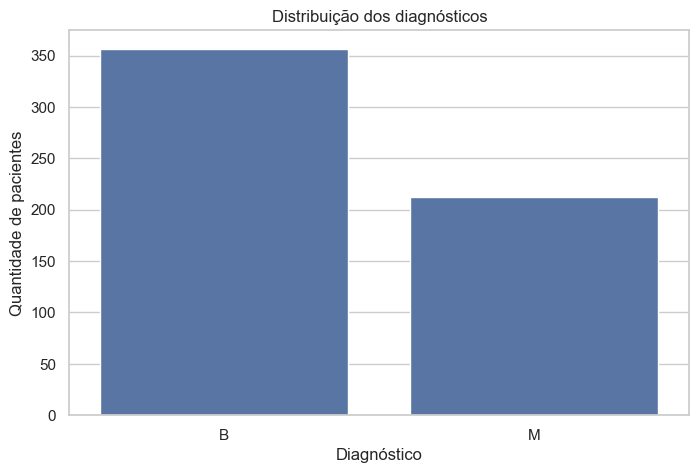

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="diagnosis",
    order=["B", "M"]
)

plt.title("Distribuição dos diagnósticos")
plt.xlabel("Diagnóstico")
plt.ylabel("Quantidade de pacientes")

plt.show()

## 5. Distribuição do raio médio

Para as próximas análises, uma cópia dos dados exclui o identificador `id` e a coluna inteiramente vazia `Unnamed: 32`. Essa preparação exploratória mantém o DataFrame original e o arquivo do dataset preservados.

In [9]:
# cópia para análise, preservando os dados originais
eda_df = df.drop(columns=["id", "Unnamed: 32"]).copy()

print(f"Linhas: {eda_df.shape[0]}")
print(f"Colunas: {eda_df.shape[1]}")

display(eda_df.head())

Linhas: 569
Colunas: 31


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


A cópia contém 569 registros e 31 colunas.

A variável `radius_mean` foi escolhida por representar uma medida de tamanho de interpretação direta. O histograma por diagnóstico permite examinar concentração, dispersão e sobreposição dos valores entre as classes. Trata-se de uma escolha para exploração inicial, sem importância preditiva previamente demonstrada.

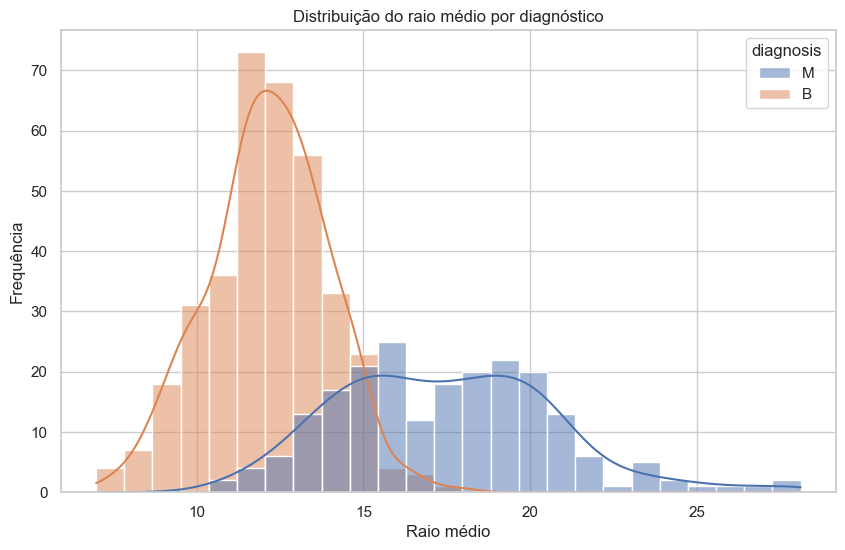

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="radius_mean",
    hue="diagnosis",
    kde=True,
    bins=25,
    common_norm=False
)

plt.title("Distribuição do raio médio por diagnóstico")
plt.xlabel("Raio médio")
plt.ylabel("Frequência")

plt.show()

**Orientação para interpretação:** observar as faixas de maior frequência, a forma das distribuições e a sobreposição entre B e M. A comparação deve considerar que as classes têm quantidades diferentes de registros; o gráfico não mede desempenho de classificação.

## 6. Área média e valores extremos

A variável `area_mean` foi escolhida como outra medida de tamanho para examinar a mediana, a dispersão e possíveis valores extremos por diagnóstico no boxplot. Essa escolha também é exploratória, sem importância preditiva previamente demonstrada. Pontos além dos limites do boxplot indicam possíveis outliers segundo o critério do gráfico, sem comprovar erros nos dados.

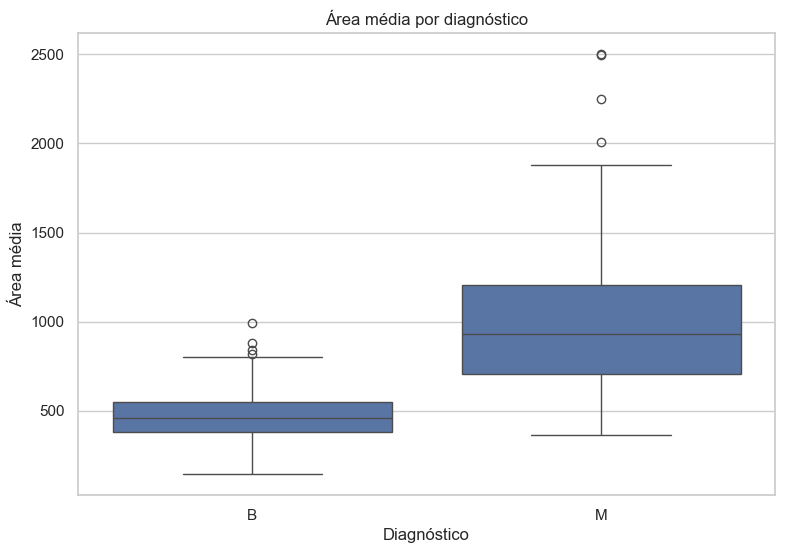

In [11]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=eda_df,
    x="diagnosis",
    y="area_mean",
    order=["B", "M"]
)

plt.title("Área média por diagnóstico")
plt.xlabel("Diagnóstico")
plt.ylabel("Área média")

plt.show()

**Orientação para interpretação:** comparar as medianas, a amplitude das caixas e os pontos além dos limites em cada classe. Eventuais valores extremos devem ser examinados em seu contexto antes de qualquer decisão de tratamento.

## 7. Correlação entre as variáveis

O diagnóstico é representado como B = 0 e M = 1 em uma cópia destinada à análise. As correlações de Pearson são ordenadas pelo valor absoluto para identificar as dez características com maior associação linear ao diagnóstico na amostra. Essa associação não demonstra causalidade nem importância preditiva validada.

In [12]:
# Converter o diagnóstico apenas para análise de correlação
correlation_df = eda_df.copy()

correlation_df["diagnosis"] = (
    correlation_df["diagnosis"]
    .map({"B": 0, "M": 1})
)

correlations = (
    correlation_df.corr(numeric_only=True)["diagnosis"]
    .drop("diagnosis")
    .sort_values(key=abs, ascending=False)
)

display(correlations.head(10))

concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
concavity_mean          0.696360
concavity_worst         0.659610
Name: diagnosis, dtype: float64

**Resultado:** entre as correlações exibidas com o diagnóstico, `concave points_worst` apresenta o maior valor (aproximadamente 0,794), seguido de `perimeter_worst` (0,783). `radius_mean` e `area_mean` apresentam, respectivamente, cerca de 0,730 e 0,709. Todos os coeficientes exibidos são positivos; com a codificação adotada, valores maiores dessas características estão associados ao diagnóstico maligno na amostra.

O mapa de calor apresenta as correlações entre as dez características selecionadas. Ele permite investigar associações entre as próprias medidas e possíveis redundâncias; não representa diretamente a correlação de cada uma com o diagnóstico.

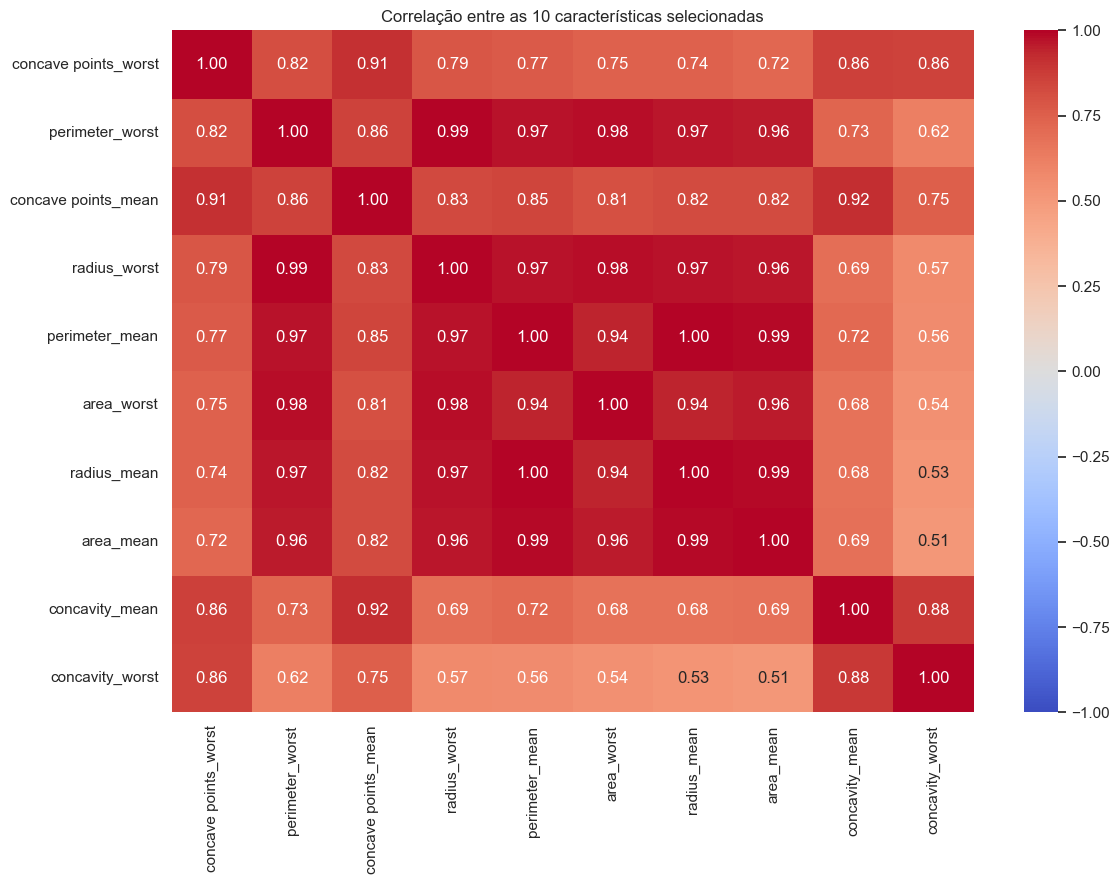

In [13]:
top_features = correlations.head(10).index.tolist()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_df[top_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre as 10 características selecionadas")

plt.tight_layout()
plt.show()

**Orientação para interpretação:** identificar pares com coeficientes próximos de 1 ou de −1 e registrar possíveis redundâncias entre as características. Essa observação, isoladamente, não define quais variáveis devem ser mantidas em um modelo.

## 8. Considerações finais

- A base analisada contém 569 registros e 33 colunas, com predominância de diagnósticos benignos: 62,74%, frente a 37,26% de malignos.
- A coluna `Unnamed: 32` está inteiramente vazia; as demais não apresentam valores ausentes. Não foram encontradas linhas integralmente duplicadas.
- As estatísticas descritivas mostram diferenças de escala entre as medidas. As comparações gráficas de `radius_mean` e `area_mean` dispõem de orientações para registrar posteriormente a interpretação visual.
- Entre as correlações com o diagnóstico exibidas, `concave points_worst` e `perimeter_worst` apresentam os maiores valores. Esses resultados descrevem associações na amostra e não estabelecem desempenho preditivo.

A análise permanece exploratória, sem definir um pré-processamento definitivo nem avaliar modelos de classificação.

In [14]:
## Conclusões da análise exploratória